# Lab 1 — Reconstruct a Synthetic Patient’s Data Journey

**AI in Healthcare · Completed lab**

All records are synthetic. Run the cells in order with Python, pandas and Matplotlib. The setup generates five CSV files and one JSON Bundle in `healthcare_ecosystem_lab_data/`.

| Check | Result |
|---|---|
| Observation audit | 7 raw rows, 1 exact duplicate, 1 missing value |
| Linked records | 6 observations across 3 patients |
| Cohort | P001 with 2 qualifying encounters |
| FHIR comparison | 2 matching observations |
| Wearable coverage | 18 of 24 expected hourly samples |

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA = Path("healthcare_ecosystem_lab_data")
DATA.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 20)
print("Teaching files:", DATA.resolve())

Teaching files: /workspace/scratch/600ca3e55f25/work/healthcare_ecosystem_lab_data


In [2]:
patients = pd.DataFrame([
    ("P001", 1980), ("P002", 1992), ("P003", 1975), ("P004", 2000)
], columns=["patient_id", "birth_year"])
encounters = pd.DataFrame([
    ("E001", "P001", "2026-01-10T09:00:00+05:30", "outpatient"),
    ("E002", "P001", "2026-02-10T10:00:00+05:30", "outpatient"),
    ("E003", "P002", "2026-01-15T11:00:00+05:30", "outpatient"),
    ("E004", "P003", "2026-01-20T09:00:00+05:30", "outpatient"),
    ("E005", "P003", "2026-03-01T09:00:00+05:30", "outpatient"),
    ("E006", "P004", "2025-12-20T09:00:00+05:30", "outpatient")
], columns=["encounter_id", "patient_id", "start", "type"])
observations = pd.DataFrame([
    ("O001", "E001", "heart_rate", 78, "beats/min", "2026-01-10T09:10:00+05:30"),
    ("O001", "E001", "heart_rate", 78, "beats/min", "2026-01-10T09:10:00+05:30"),
    ("O002", "E001", "temperature", 37, "Cel", "2026-01-10T09:12:00+05:30"),
    ("O003", "E002", "heart_rate", None, "beats/min", "2026-02-10T10:10:00+05:30"),
    ("O004", "E003", "temperature", 98.6, "[degF]", "2026-01-15T11:10:00+05:30"),
    ("O005", "E004", "heart_rate", 84, "beats/min", "2026-01-20T09:10:00+05:30"),
    ("O006", "E005", "heart_rate", 80, "beats/min", "2026-03-01T09:10:00+05:30")
], columns=["observation_id", "encounter_id", "code", "value", "unit", "effective_time"])
notes = pd.DataFrame([
    ("N001", "P001", "E001", "No history of diabetes. Patient reports reduced activity."),
    ("N002", "P001", "E002", "Follow-up visit. Further assessment planned."),
    ("N003", "P002", "E003", "Family history of diabetes; patient history not established.")
], columns=["note_id", "patient_id", "encounter_id", "text"])
times = pd.date_range("2026-01-10T00:00:00+05:30", periods=24, freq="h")
wearable = pd.DataFrame({"patient_id": "P001", "time": times,
                         "steps": [0,0,0,0,0,20,100,250,300,150,80,120,
                                   200,180,90,140,220,400,350,200,100,40,10,0]})
# Deliberately omit six expected hourly samples. A gap is not a zero.
wearable = wearable.drop(index=range(12,18)).reset_index(drop=True)
for name, frame in {"patients":patients, "encounters":encounters,
                    "observations":observations, "notes":notes, "wearable":wearable}.items():
    frame.to_csv(DATA / f"{name}.csv", index=False)

# Small R4-style collection Bundle, separate from the intentionally messy CSV.
# Educational examples; no formal FHIR/profile validator is run here.
resources = [{"resourceType":"Patient", "id":p} for p in patients.patient_id]
for row in encounters.itertuples():
    resources.append({"resourceType":"Encounter", "id":row.encounter_id,
        "status":"finished", "class":{"system":"http://terminology.hl7.org/CodeSystem/v3-ActCode",
        "code":"AMB"}, "subject":{"reference":f"Patient/{row.patient_id}"},
        "period":{"start":row.start}})
for oid, pid, eid, value, time in [
    ("O001","P001","E001",78,"2026-01-10T09:10:00+05:30"),
    ("O005","P003","E004",84,"2026-01-20T09:10:00+05:30")]:
    resources.append({"resourceType":"Observation", "id":oid, "status":"final",
        "code":{"coding":[{"system":"http://loinc.org", "code":"8867-4", "display":"Heart rate"}]},
        "subject":{"reference":f"Patient/{pid}"},
        "encounter":{"reference":f"Encounter/{eid}"}, "effectiveDateTime":time,
        "valueQuantity":{"value":value, "unit":"beats/minute",
        "system":"http://unitsofmeasure.org", "code":"/min"}})
bundle = {"resourceType":"Bundle", "type":"collection", "entry":[
    {"fullUrl":f"https://example.org/fhir/{r['resourceType']}/{r['id']}", "resource":r}
    for r in resources]}
(DATA / "patient_bundle.json").write_text(json.dumps(bundle, indent=2), encoding="utf-8")
print("Created five CSV files and one JSON file.")

Created five CSV files and one JSON file.


## 1. Inventory (0–15 minutes)

Load the generated files as if another team had supplied them. Identify the meaning of one row in each table. Are these sources, representations, or both?

In [3]:
tables = {name: pd.read_csv(DATA / f"{name}.csv")
          for name in ["patients", "encounters", "observations", "notes", "wearable"]}

for name, frame in tables.items():
    print(name, frame.shape)
    display(frame.head(3))
    
patients, encounters, observations, notes, wearable = [tables[n] for n in tables]
encounters["start"] = pd.to_datetime(encounters["start"], utc=True)
observations["effective_time"] = pd.to_datetime(observations["effective_time"], utc=True)
wearable["time"] = pd.to_datetime(wearable["time"], utc=True)

patients (4, 2)


,patient_id,birth_year
0,P001,1980
1,P002,1992
2,P003,1975


encounters (6, 4)


,encounter_id,patient_id,start,type
0,E001,P001,2026-01-10T09:00:00+05:30,outpatient
1,E002,P001,2026-02-10T10:00:00+05:30,outpatient
2,E003,P002,2026-01-15T11:00:00+05:30,outpatient


observations (7, 6)


,observation_id,encounter_id,code,value,unit,effective_time
0,O001,E001,heart_rate,78.0,beats/min,2026-01-10T09:10:00+05:30
1,O001,E001,heart_rate,78.0,beats/min,2026-01-10T09:10:00+05:30
2,O002,E001,temperature,37.0,Cel,2026-01-10T09:12:00+05:30


notes (3, 4)


,note_id,patient_id,encounter_id,text
0,N001,P001,E001,No history of diabetes. Patient reports reduce...
1,N002,P001,E002,Follow-up visit. Further assessment planned.
2,N003,P002,E003,Family history of diabetes; patient history no...


wearable (18, 3)


,patient_id,time,steps
0,P001,2026-01-10 00:00:00+05:30,0
1,P001,2026-01-10 01:00:00+05:30,0
2,P001,2026-01-10 02:00:00+05:30,0


### Student response

| File | What one row or entry represents | Identifier(s) | Representation and example use |
|---|---|---|---|
| `patients.csv` | One synthetic patient | `patient_id` | Structured demographics extract. Provides the patient roster and a key for linking visits. |
| `encounters.csv` | One healthcare visit | `encounter_id` and patient reference `patient_id` | Structured encounter extract. Supports visit counts and index-date selection. |
| `observations.csv` | One exported measurement record, including a duplicate or an absent value | Intended key `observation_id` and visit reference `encounter_id` | Structured measurement extract. Supports analysis by measurement code after unit harmonization. |
| `notes.csv` | One note associated with a visit | `note_id`, `patient_id`, `encounter_id` | Structured metadata with free-text narrative. Supports contextual review of documented history. |
| `wearable.csv` | One supplied hourly step count for a patient | Composite key `(patient_id, time)` | Structured device time series. Supports activity and sample coverage analysis. |
| `patient_bundle.json` | One Bundle entry carrying a Patient, Encounter or Observation resource | Resource type and `id`, plus entry `fullUrl` | Nested FHIR-style JSON. Supports resource exchange and reference resolution. |

The tables and Bundle are the files supplied for the analysis, so they serve as its inputs. CSV and FHIR JSON are representations of underlying sources such as clinical documentation, measurement systems and wearable devices. In `notes.csv`, the note has a structured envelope but the narrative still expresses concepts, negation and family relationships in free text.

The companion lecture file was unavailable. Examples of source categories absent from the fixture include medical images, insurance claims and billing, pharmacy or medication dispensing records, genomics, and disease registries.

## 2. Data dictionary and quality audit (15–35 minutes)

Create a dictionary for at least eight columns across three files: meaning, type, unit (if applicable), key role, and missingness interpretation.

Inspect exact duplicate rows, repeated observation IDs, missing values, and measurement units. Do not fill missing measurements with zero.

In [4]:
print("Exact duplicate observation rows:", observations.duplicated().sum())
print("Repeated observation IDs:", observations.observation_id.duplicated().sum())
display(observations.isna().sum().rename("missing_count").to_frame())
display(observations.groupby(["code", "unit"]).size().rename("rows").reset_index())
display(notes.assign(keyword_diabetes=notes.text.str.contains("diabetes", case=False)))

Exact duplicate observation rows: 1
Repeated observation IDs: 1


,missing_count
observation_id,0
encounter_id,0
code,0
value,1
unit,0
effective_time,0


,code,unit,rows
0,heart_rate,beats/min,5
1,temperature,Cel,1
2,temperature,[degF],1


,note_id,patient_id,encounter_id,text,keyword_diabetes
0,N001,P001,E001,No history of diabetes. Patient reports reduce...,True
1,N002,P001,E002,Follow-up visit. Further assessment planned.,False
2,N003,P002,E003,Family history of diabetes; patient history no...,True


In [5]:
data_dictionary = pd.DataFrame([
    ("patients.csv", "patient_id", "Synthetic patient identifier", "string", "—", "Primary key", "Patient cannot be uniquely identified"),
    ("patients.csv", "birth_year", "Calendar year of birth", "integer", "year", "None", "Birth year is unavailable"),
    ("encounters.csv", "encounter_id", "Synthetic visit identifier", "string", "—", "Primary key", "Visit cannot be uniquely identified"),
    ("encounters.csv", "patient_id", "Patient associated with visit", "string", "—", "Foreign key to patients", "Patient association is unavailable"),
    ("encounters.csv", "start", "Visit start time", "datetime with timezone", "—", "None", "Visit cannot be classified by the time window"),
    ("observations.csv", "observation_id", "Synthetic observation identifier", "string", "—", "Intended primary key", "Observation identity is unavailable"),
    ("observations.csv", "encounter_id", "Visit associated with observation", "string", "—", "Foreign key to encounters", "Observation cannot be linked to a visit by this key"),
    ("observations.csv", "code", "Local measurement concept", "string", "—", "None", "Meaning of the measurement is unknown"),
    ("observations.csv", "value", "Numeric result interpreted with code and unit", "float", "See unit column", "None", "No numeric result supplied. Reason is unspecified."),
    ("observations.csv", "unit", "Unit of the numeric result", "string", "beats/min, Cel, [degF]", "None", "Measurement scale is unspecified"),
    ("observations.csv", "effective_time", "Time associated with the observation", "datetime with timezone", "—", "None", "Observation cannot be placed on a timeline"),
    ("wearable.csv", "patient_id", "Patient associated with sample", "string", "—", "Composite key part, foreign key to patients", "Sample cannot be assigned to a patient"),
    ("wearable.csv", "time", "Hourly sample timestamp", "datetime with timezone", "—", "Composite key part", "Sample cannot be assigned to an hour"),
    ("wearable.csv", "steps", "Step count for the hourly interval", "integer", "steps", "None", "Hourly step count is unavailable"),
], columns=["file", "column", "meaning", "type", "unit", "key_role", "missing_meaning"])
with pd.option_context("display.max_colwidth", None):
    display(data_dictionary)

,file,column,meaning,type,unit,key_role,missing_meaning
0,patients.csv,patient_id,Synthetic patient identifier,string,—,Primary key,Patient cannot be uniquely identified
1,patients.csv,birth_year,Calendar year of birth,integer,year,None,Birth year is unavailable
2,encounters.csv,encounter_id,Synthetic visit identifier,string,—,Primary key,Visit cannot be uniquely identified
3,encounters.csv,patient_id,Patient associated with visit,string,—,Foreign key to patients,Patient association is unavailable
4,encounters.csv,start,Visit start time,datetime with timezone,—,None,Visit cannot be classified by the time window
5,observations.csv,observation_id,Synthetic observation identifier,string,—,Intended primary key,Observation identity is unavailable
6,observations.csv,encounter_id,Visit associated with observation,string,—,Foreign key to encounters,Observation cannot be linked to a visit by this key
7,observations.csv,code,Local measurement concept,string,—,None,Meaning of the measurement is unknown
8,observations.csv,value,Numeric result interpreted with code and unit,float,See unit column,None,No numeric result supplied. Reason is unspecified.
9,observations.csv,unit,Unit of the numeric result,string,"beats/min, Cel, [degF]",None,Measurement scale is unspecified


In [6]:
temperatures = observations.loc[observations.code.eq("temperature")].copy()
assert temperatures.unit.isin(["Cel", "[degF]"]).all()
fahrenheit = temperatures.unit.eq("[degF]")
temperatures["value_celsius"] = temperatures.value
temperatures.loc[fahrenheit, "value_celsius"] = (
    (temperatures.loc[fahrenheit, "value"] - 32) * 5 / 9
)
display(temperatures[["observation_id", "value", "unit", "value_celsius"]])

,observation_id,value,unit,value_celsius
2,O002,37.0,Cel,37.0
4,O004,98.6,[degF],37.0


### Student response

1. The second copy of O001 is an exact duplicate export row. Including it would double-count that measurement.
2. O003 records a heart-rate observation with an absent numeric value. The fixture gives no reason for the missing value, so it remains missing.
3. The two temperatures use Celsius and Fahrenheit. O002 is 37.0 °C and O004 converts from 98.6 °F to 37.0 °C. The original values and units are retained.
4. The diabetes keyword matches N001, which negates a patient history of diabetes, and N003, which documents family history and leaves the patient's history unestablished. Neither match establishes a diagnosis. The absence of a keyword in N002 also leaves disease status unresolved.
5. The wearable export omits six expected hours. The other hours include genuine recorded zero counts.

Removal is justified when field-by-field comparison and source provenance establish that the two rows represent the same event copied during export. The generator establishes that provenance for O001, whose two rows agree across every field. A conflicting repeated ID requires investigation of revisions, source records or key collisions before discarding anything.

In [7]:
clean_obs = observations.drop_duplicates().copy()
assert clean_obs.observation_id.is_unique
assert patients.patient_id.is_unique
assert encounters.encounter_id.is_unique
print("Raw rows:", len(observations), "After exact deduplication:", len(clean_obs))

Raw rows: 7 After exact deduplication: 6


## 3. Link records without changing their meaning (35–60 minutes)

First attach each encounter to a patient, then attach each observation to its encounter. `validate="many_to_one"` checks that the right-hand keys are unique. The merge indicator checks whether references matched; cardinality validation alone does not check that.

In [8]:
encounter_patient = encounters.merge(patients, on="patient_id", how="left",
                                      validate="many_to_one", indicator=True)
assert encounter_patient["_merge"].eq("both").all()
encounter_patient = encounter_patient.drop(columns="_merge")
linked = clean_obs.merge(encounter_patient, on="encounter_id", how="left",
                         validate="many_to_one", indicator=True)
assert linked["_merge"].eq("both").all()
assert len(linked) == len(clean_obs)
linked = linked.drop(columns="_merge")
display(linked)
print("Rows:", len(linked), "Distinct patients:", linked.patient_id.nunique())

,observation_id,encounter_id,code,value,unit,effective_time,patient_id,start,type,birth_year
0,O001,E001,heart_rate,78.0,beats/min,2026-01-10 03:40:00+00:00,P001,2026-01-10 03:30:00+00:00,outpatient,1980
1,O002,E001,temperature,37.0,Cel,2026-01-10 03:42:00+00:00,P001,2026-01-10 03:30:00+00:00,outpatient,1980
2,O003,E002,heart_rate,NaN,beats/min,2026-02-10 04:40:00+00:00,P001,2026-02-10 04:30:00+00:00,outpatient,1980
3,O004,E003,temperature,98.6,[degF],2026-01-15 05:40:00+00:00,P002,2026-01-15 05:30:00+00:00,outpatient,1992
4,O005,E004,heart_rate,84.0,beats/min,2026-01-20 03:40:00+00:00,P003,2026-01-20 03:30:00+00:00,outpatient,1975
5,O006,E005,heart_rate,80.0,beats/min,2026-03-01 03:40:00+00:00,P003,2026-03-01 03:30:00+00:00,outpatient,1975


Rows: 6 Distinct patients: 3


In [9]:
bad_join = encounters.merge(notes[["patient_id", "note_id"]], on="patient_id", how="left")

# Verify that each note's patient agrees with the patient for its encounter.
note_check = notes.merge(
    encounters[["encounter_id", "patient_id"]], on="encounter_id",
    how="left", validate="many_to_one", indicator=True,
    suffixes=("_note", "_encounter"),
)
assert note_check["_merge"].eq("both").all()
assert note_check.patient_id_note.eq(note_check.patient_id_encounter).all()

correct_notes = encounters.merge(
    notes[["encounter_id", "note_id", "text"]],
    on="encounter_id", how="left", validate="one_to_many",
)

p1_bad = bad_join.loc[bad_join.patient_id.eq("P001")]
p1_correct = correct_notes.loc[correct_notes.patient_id.eq("P001")]
columns = ["patient_id", "encounter_id", "note_id"]
print(f"Patient-only join for P001 ({len(p1_bad)} rows)")
display(p1_bad[columns])
print(f"Encounter-based join for P001 ({len(p1_correct)} rows)")
display(p1_correct[columns])

Patient-only join for P001 (4 rows)


,patient_id,encounter_id,note_id
0,P001,E001,N001
1,P001,E001,N002
2,P001,E002,N001
3,P001,E002,N002


Encounter-based join for P001 (2 rows)


,patient_id,encounter_id,note_id
0,P001,E001,N001
1,P001,E002,N002


### Student response

Each row of `linked` represents one deduplicated observation with its encounter and patient details. The six observations refer to P001, P002 and P003. P004 appears in the roster and has encounter E006, which has no observations. To retain all patients, start with the patient roster and left-join encounters by `patient_id`, then observations by `encounter_id`. Patients and encounters without child records remain with empty child fields. The result can have several rows per patient, so aggregate observations first if a one-row-per-patient table is needed.

The patient-only join pairs both P001 encounters with both notes, creating four rows. It wrongly assigns N002 to E001 and N001 to E002. Joining on the encounter ID gives two rows, E001–N001 and E002–N002. The one-to-many validation allows several legitimate notes per encounter while requiring encounter IDs to be unique on the encounter side.

## 4. Define a reproducible cohort (60–80 minutes)

**Rule:** Include patients with at least two distinct encounters starting in the half-open interval **[1 January 2026, 1 March 2026)**, measured in Asia/Kolkata local time. Count encounters, not observations. The end boundary is excluded.

Implement the rule in the next cell. Then report included IDs and explain boundary handling. This is a record-availability cohort, not a disease cohort.

In [10]:
window_start = pd.Timestamp("2026-01-01", tz="Asia/Kolkata").tz_convert("UTC")
window_end = pd.Timestamp("2026-03-01", tz="Asia/Kolkata").tz_convert("UTC")
eligible = encounters.loc[encounters.start.ge(window_start) & encounters.start.lt(window_end)]
counts = eligible.groupby("patient_id").encounter_id.nunique()
all_counts = counts.reindex(patients.patient_id, fill_value=0).rename("encounter_count")
cohort = all_counts[all_counts.ge(2)].reset_index()

print(f"UTC window: [{window_start}, {window_end})")
print("Distinct qualifying visits per patient")
display(all_counts.reset_index())
print("Included cohort")
display(cohort)

UTC window: [2025-12-31 18:30:00+00:00, 2026-02-28 18:30:00+00:00)
Distinct qualifying visits per patient


,patient_id,encounter_count
0,P001,2
1,P002,1
2,P003,1
3,P004,0


Included cohort


,patient_id,encounter_count
0,P001,2


### Student response

**P001** is the only eligible patient, with E001 on 10 January and E002 on 10 February. The rule includes starts at or after midnight on 1 January and strictly before midnight on 1 March in Asia/Kolkata. P003 has one eligible January visit, E004. E005 starts at 09:00 local time on 1 March, nine hours after the excluded upper bound. P002 has one qualifying visit and P004 has zero.

An observation-level join can multiply visits with several measurements and omit visits without measurements. For example, E001 has two rows in `linked`, while E006 has none. The cohort rule measures documented visit frequency in a synthetic export. It uses no disease outcome, follow-up or representative population from which to estimate risk.

## 5. Read FHIR JSON (80–100 minutes)

The collection Bundle packages Patient, Encounter, and Observation resources. The extraction below handles only the simple reference and quantity pattern in this fixture. Production FHIR supports additional reference forms, value types, optional fields, and profiles.

FHIR R4 references: [Observation](https://hl7.org/fhir/R4/observation.html), [Bundle](https://hl7.org/fhir/R4/bundle.html). Successful JSON parsing is not formal FHIR validation.

In [11]:
bundle_loaded = json.loads((DATA / "patient_bundle.json").read_text(encoding="utf-8"))
resource_index = {f"{e['resource']['resourceType']}/{e['resource']['id']}": e["resource"]
                  for e in bundle_loaded["entry"]}
fhir_rows = []
for resource in resource_index.values():
    if resource["resourceType"] != "Observation":
        continue
    patient_ref = resource["subject"]["reference"]
    encounter_ref = resource["encounter"]["reference"]
    assert patient_ref in resource_index and encounter_ref in resource_index
    assert resource_index[encounter_ref]["subject"]["reference"] == patient_ref
    coding = next(c for c in resource["code"]["coding"] if c["system"] == "http://loinc.org")
    q = resource["valueQuantity"]
    fhir_rows.append({"observation_id":resource["id"],
        "patient_id":patient_ref.split("/")[-1], "encounter_id":encounter_ref.split("/")[-1],
        "loinc_code":coding["code"], "value":q["value"], "ucum_code":q["code"],
        "effective_time":resource["effectiveDateTime"]})
fhir_frame = pd.DataFrame(fhir_rows)
fhir_frame["effective_time"] = pd.to_datetime(fhir_frame["effective_time"], utc=True)
display(fhir_frame)

,observation_id,patient_id,encounter_id,loinc_code,value,ucum_code,effective_time
0,O001,P001,E001,8867-4,78,/min,2026-01-10 03:40:00+00:00
1,O005,P003,E004,8867-4,84,/min,2026-01-20 03:40:00+00:00


In [12]:
# Explicit mappings apply only to the codes/units in this teaching fixture.
comparison_source = linked.copy()
comparison_source["loinc_code"] = comparison_source.code.map({"heart_rate":"8867-4"})
comparison_source["ucum_code"] = comparison_source.unit.map({"beats/min":"/min"})
comparison = fhir_frame.merge(comparison_source, on="observation_id", how="left",
                              suffixes=("_fhir", "_csv"), validate="one_to_one", indicator=True)
assert comparison["_merge"].eq("both").all()
for field in ["patient_id", "encounter_id", "loinc_code", "value", "ucum_code", "effective_time"]:
    assert comparison[f"{field}_fhir"].eq(comparison[f"{field}_csv"]).all(), field
print("Both FHIR observations agree with their CSV counterparts on identity, code, value, unit, and time.")

Both FHIR observations agree with their CSV counterparts on identity, code, value, unit, and time.


In [13]:
sample = resource_index["Observation/O001"]
display({
    "subject.reference": sample["subject"]["reference"],
    "encounter.reference": sample["encounter"]["reference"],
    "code.coding[0]": sample["code"]["coding"][0],
    "valueQuantity": sample["valueQuantity"],
})

{'subject.reference': 'Patient/P001', 'encounter.reference': 'Encounter/E001', 'code.coding[0]': {'system': 'http://loinc.org', 'code': '8867-4', 'display': 'Heart rate'}, 'valueQuantity': {'value': 78, 'unit': 'beats/minute', 'system': 'http://unitsofmeasure.org', 'code': '/min'}}

### Student response

Within an Observation entry at `entry[i].resource`, the following paths locate the requested fields. For O001, they contain:

| Field | JSON path | Value |
|---|---|---|
| Subject reference | `subject.reference` | `Patient/P001` |
| Encounter reference | `encounter.reference` | `Encounter/E001` |
| Measurement coding | `code.coding[0].system` and `code.coding[0].code` | `http://loinc.org` and `8867-4` (heart rate) |
| Quantity | `valueQuantity` | `value: 78`, `unit: beats/minute`, `system: http://unitsofmeasure.org`, `code: /min` |

A coded unit supplies a machine-comparable identifier within its coding system. Display labels can vary, as in CSV `beats/min` and JSON `beats/minute`. The fixture mapping compares both as UCUM `/min`.

The generator deliberately includes only O001 and O005 in the Bundle, while the CSV contains seven raw rows and six distinct observations after deduplication. The check establishes agreement for selected fields in the two overlapping records. Completeness would require an expected record set, clinical validity would require evidence beyond matching files, and formal FHIR conformance would require validation.

## 6. Visualize a journey and missing samples (100–115 minutes)

We know from the synthetic generator that one sample per hour was expected. In real data, verify the expected sampling schedule before calling absent timestamps “missing.” Times below are shown in Asia/Kolkata.

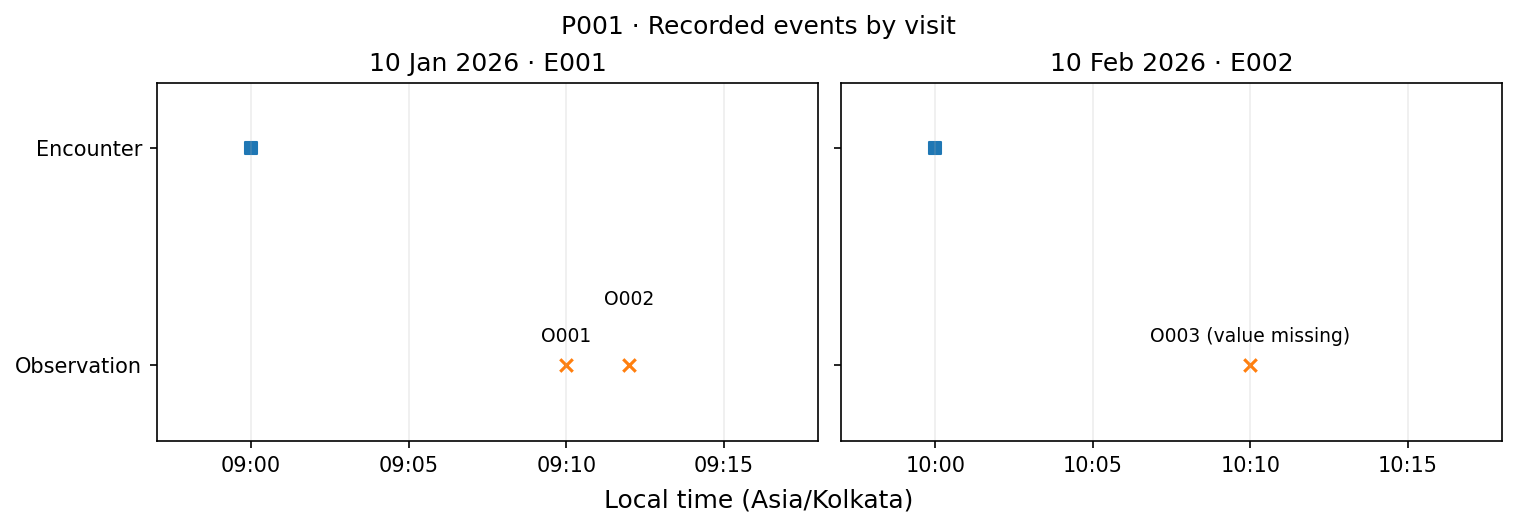

In [14]:
import matplotlib.dates as mdates
from zoneinfo import ZoneInfo

local_zone = ZoneInfo("Asia/Kolkata")
p1_encounters = encounters.loc[encounters.patient_id.eq("P001")].sort_values("start")
p1_obs = linked.loc[linked.patient_id.eq("P001")]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True, layout="constrained")
for ax, encounter in zip(axes, p1_encounters.itertuples(index=False)):
    start = encounter.start.tz_convert(local_zone)
    event_rows = p1_obs.loc[p1_obs.encounter_id.eq(encounter.encounter_id)]
    event_times = event_rows.effective_time.dt.tz_convert(local_zone)
    ax.scatter([start], [1], marker="s", color="tab:blue")
    ax.scatter(event_times, [0] * len(event_rows), marker="x", color="tab:orange")
    for index, (row, time) in enumerate(zip(event_rows.itertuples(index=False), event_times)):
        label = row.observation_id + (" (value missing)" if pd.isna(row.value) else "")
        ax.annotate(label, (time, 0), xytext=(0, 11 + 18 * index),
                    textcoords="offset points", ha="center", fontsize=9)
    ax.set(title=f"{start:%d %b %Y} · {encounter.encounter_id}", ylim=(-0.35, 1.3),
           xlim=(start - pd.Timedelta(minutes=3), start + pd.Timedelta(minutes=18)))
    ax.set_yticks([0, 1], ["Observation", "Encounter"])
    ax.xaxis.set_major_locator(mdates.MinuteLocator(byminute=range(0, 60, 5), tz=local_zone))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=local_zone))
    ax.grid(axis="x", alpha=0.22)
fig.suptitle("P001 · Recorded events by visit")
fig.supxlabel("Local time (Asia/Kolkata)")
plt.show()

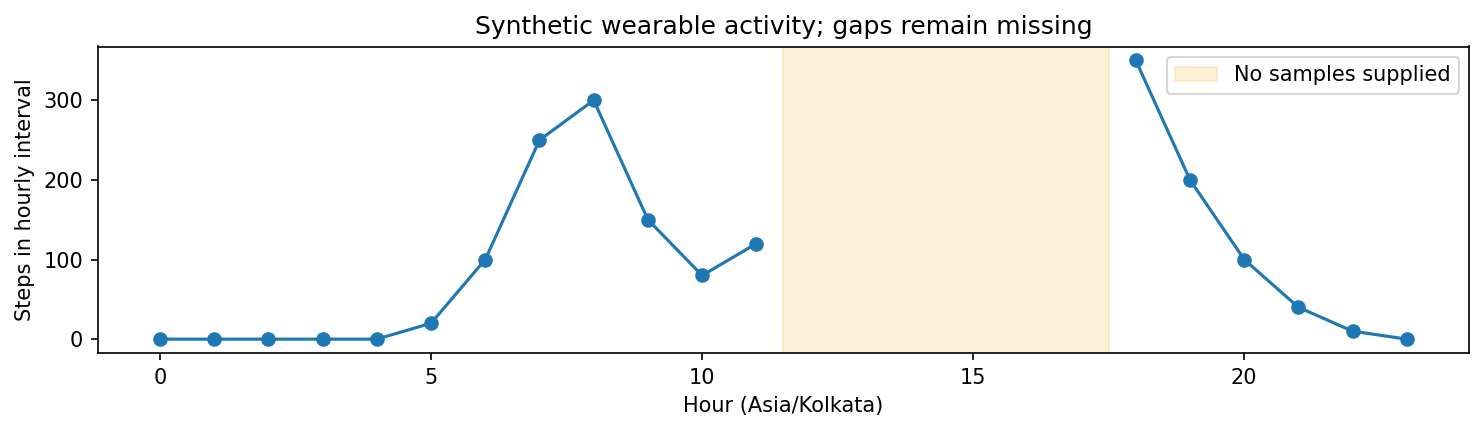

Missing expected hourly samples: 6
Missing local hours: 12:00, 13:00, 14:00, 15:00, 16:00, 17:00


In [15]:
expected = pd.date_range("2026-01-10", periods=24, freq="h", tz="Asia/Kolkata")
series = wearable.set_index("time")["steps"].tz_convert("Asia/Kolkata").reindex(expected)
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(series.index.hour, series.values, marker="o")
ax.axvspan(11.5, 17.5, alpha=0.15, color="orange", label="No samples supplied")
ax.set(xlabel="Hour (Asia/Kolkata)", ylabel="Steps in hourly interval", title="Synthetic wearable activity; gaps remain missing")
ax.legend()
plt.tight_layout()
plt.show()
print("Missing expected hourly samples:", series.isna().sum())
print("Missing local hours:", ", ".join(series.index[series.isna()].strftime("%H:%M")))

### Student response

The orange region covers the six expected samples at 12:00 through 17:00 local time on 10 January. The plot breaks between the 11:00 and 18:00 measurements because those intervening values are missing. Replacing them with zeros would falsely suggest a six-hour period of recorded inactivity and could understate daily activity.

O003 appears at 10:10 local time on 10 February because its observation record and timestamp are present. The timeline depicts recorded events, including O003, whose heart-rate value is absent.

## 7. Final reflection

Flattening the FHIR observations kept the patient and encounter IDs, measurement and unit codes, numeric result, and effective time. It dropped the observation status, Bundle entry full URLs, complete reference strings, display labels, and coding-system URIs. The linked Patient and Encounter resources stayed in the JSON, so a row in the flat table carries less context than the original resource and its links.

Three limitations would matter before training a model. First, four invented patients provide no evidence that the cohort represents the population where a model would be used. Second, coverage varies by source. Wearable data are available for one patient and omit six hours, while observation values can be missing even when a visit is documented. In real data, those gaps could be related to the device, care workflow, or patient behavior. Third, reliable labels and consistent inputs require explicit definitions. For example, a diabetes keyword flags both negation and family history, and raw temperatures use two unit scales.

At encounter start, a measurement taken ten minutes later would be unavailable. Including it in training for that prediction point would leak future information. A real system also needs a result availability timestamp, such as when the result was released to the source system or ingested by the prediction pipeline, depending on which system serves the model.

In [16]:
assert len(observations) == 7 and observations.duplicated().sum() == 1
assert len(clean_obs) == 6 and linked.patient_id.nunique() == 3
assert temperatures.value_celsius.eq(37).all()
assert len(p1_bad) == 4 and len(p1_correct) == 2
assert cohort.to_dict("records") == [{"patient_id": "P001", "encounter_count": 2}]
assert len(comparison) == 2
assert series.isna().sum() == 6 and series.notna().sum() == 18
print("All lab checks passed.")

All lab checks passed.
